In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
import rasterio.features as features

## Open data

In [18]:
path_SCFV_data = 'C:/Users/minttu/Documents/Gac_data/1985/*.nc'

In [3]:
path_area = 'C:/Users/minttu/Documents/Transmissivity_map_areas/Kemijoki_4326/Kemijoki_grid_5000.shp'

In [20]:
ds = xr.open_mfdataset(path_SCFV_data)

C:\Users\minttu\AppData\Local\Temp\ipykernel_17524\2272215489.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xr.open_mfdataset(path_SCFV_data)


In [5]:
area = gpd.read_file(path_area)

In [6]:
print(area.crs)

EPSG:4326


In [7]:
ds

<xarray.Dataset> Size: 22GB
Dimensions:        (time: 35, lat: 3600, nv: 2, lon: 7200)
Coordinates:
  * time           (time) datetime64[ns] 280B 1985-02-25 ... 1985-03-31
  * lat            (lat) float64 29kB -89.97 -89.93 -89.88 ... 89.88 89.93 89.97
  * lon            (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Dimensions without coordinates: nv
Data variables:
    lat_bnds       (time, lat, nv) float64 2MB dask.array<chunksize=(1, 3600, 2), meta=np.ndarray>
    lon_bnds       (time, lon, nv) float64 4MB dask.array<chunksize=(1, 7200, 2), meta=np.ndarray>
    scfv           (time, lat, lon) float32 4GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    scfv_unc       (time, lat, lon) float32 4GB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    scanline_time  (time, lat, lon) float64 7GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    satzen         (time, lat, lon) float64 7GB dask.array<chunksize=(1, 1200, 2400), meta=np.ndarray>
    spatial_ref    (time) int32 140B -2147483647 -2147483647 ... -2147483647
Attributes: (12/42)
    title:                      ESA CCI viewable snow product level L3C from ...
    institution:                Remote Sensing Research Group, Institute of G...
    source:                     EUMETSAT (2023): AVHRR Fundamental Data Recor...
    date_created:               20250218T183000Z
    history:                    20250218T183000Z: ESA snow_cci SCF processing...
    references:                 http://snow-cci.enveo.at/
    ...                         ...
    license:                    ESA CCI Data Policy: free and open access
    platform:                   NOAA-9 > National Oceanic & Atmospheric Admin...
    sensor:                     AVHRR > Advanced Very High Resolution Radiometer
    spatial_resolution:         0.05 degree
    key_variables:              scfv
    doi:                        10.5285/3c71c04cf08a410fac2c680cbf88cfd7

In [114]:
area

,id,left,top,right,bottom,geometry
0,1.0,340000.0,7645000.0,345000.0,7640000.0,"POLYGON ((23.02061 68.86953, 23.14461 68.87239..."
1,2.0,340000.0,7640000.0,345000.0,7635000.0,"POLYGON ((23.02864 68.8248, 23.15239 68.82765,..."
2,3.0,340000.0,7635000.0,345000.0,7630000.0,"POLYGON ((23.03664 68.78006, 23.16014 68.78291..."
3,4.0,340000.0,7630000.0,345000.0,7625000.0,"POLYGON ((23.04459 68.73533, 23.16785 68.73817..."
4,5.0,340000.0,7625000.0,345000.0,7620000.0,"POLYGON ((23.05252 68.69059, 23.17553 68.69342..."
...,...,...,...,...,...,...
4195,4196.0,635000.0,7320000.0,640000.0,7315000.0,"POLYGON ((29.97209 65.97211, 30.08198 65.96994..."
4196,4197.0,635000.0,7315000.0,640000.0,7310000.0,"POLYGON ((29.96689 65.92731, 30.07659 65.92515..."
4197,4198.0,635000.0,7310000.0,640000.0,7305000.0,"POLYGON ((29.96171 65.88251, 30.07122 65.88036..."
4198,4199.0,635000.0,7305000.0,640000.0,7300000.0,"POLYGON ((29.95655 65.83771, 30.06586 65.83556..."


## Mask data (Clouds, shadows)

## Remove outliers

## Calculate transmissivity with SCAmod method

t2 = (obs_refl * forest_refl) / (snow_refl - forest_refl)

Reference reflectancies from ATBD

𝝆𝝀,𝒇𝒐𝒓𝒆𝒔𝒕 0.08 𝝆𝝀,𝒈𝒓𝒐𝒖𝒏𝒅 0.10 𝝆𝝀,𝒔𝒏𝒐𝒘 0.65

## Plot the results

In [9]:
da = ds["scfv"]

da = da.rio.set_spatial_dims(
    x_dim="lon",
    y_dim="lat"
)

da = da.rio.write_crs("EPSG:4326")

clipped = da.rio.clip(
    area.geometry,
    area.crs,
    drop=True
)

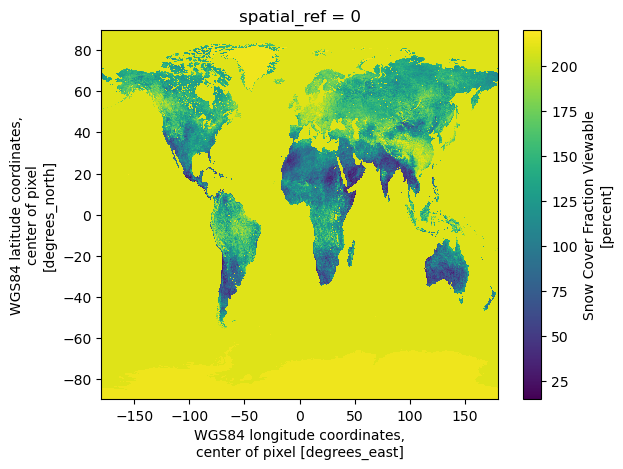

In [116]:
da.mean(dim="time").plot()

In [10]:
print(da.rio.crs)

EPSG:4326


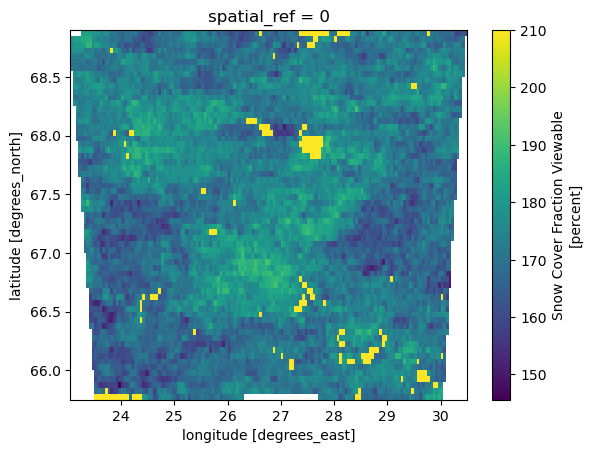

In [124]:
clipped.mean(dim="time").plot()

## Plot reflectancies and angles